In [1]:
import pandas as pd
df = pd.read_csv("supermarket_sales - Sheet1.csv")
print("Size:", df.shape)
df.head()

Size: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [2]:
# Column names
print(df.columns.tolist())

# What kind of values does each column hold?
print()
print(df.dtypes)

['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Invoice ID                  object
Branch                      object
City                        object
Customer type               object
Gender                      object
Product line                object
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                        object
Time                        object
Payment                     object
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object


In [3]:
# Empty cells in each column
print(df.isnull().sum())

# Repeated rows
print("\nRepeated rows:", df.duplicated().sum())

Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Repeated rows: 0


In [4]:
# What different values are in each text column?
for col in ["Branch", "City", "Customer type", "Gender", "Product line", "Payment"]:
    print(col, "->", df[col].unique().tolist())
    print()

Branch -> ['A', 'C', 'B']

City -> ['Yangon', 'Naypyitaw', 'Mandalay']

Customer type -> ['Member', 'Normal']

Gender -> ['Female', 'Male']

Product line -> ['Health and beauty', 'Electronic accessories', 'Home and lifestyle', 'Sports and travel', 'Food and beverages', 'Fashion accessories']

Payment -> ['Ewallet', 'Cash', 'Credit card']



In [6]:
df[["Unit price", "Quantity", "Total", "Rating"]].describe()

,Unit price,Quantity,Total,Rating
count,1000.000000,1000.000000,1000.000000,1000.00000
mean,55.672130,5.510000,322.966749,6.97270
std,26.494628,2.923431,245.885335,1.71858
min,10.080000,1.000000,10.678500,4.00000
25%,32.875000,3.000000,124.422375,5.50000
50%,55.230000,5.000000,253.848000,7.00000
75%,77.935000,8.000000,471.350250,8.50000
max,99.960000,10.000000,1042.650000,10.00000


In [7]:
print(df["Date"].head())
print(df["Date"].dtype)

0     1/5/2019
1     3/8/2019
2     3/3/2019
3    1/27/2019
4     2/8/2019
Name: Date, dtype: object
object


In [8]:
# Turn the text into real dates (month/day/year)
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")

# Add two helpful columns made from the date
df["Month"] = df["Date"].dt.month_name()
df["Weekday"] = df["Date"].dt.day_name()

# Check the result
print(df["Date"].dtype)
df[["Date", "Month", "Weekday"]].head()

datetime64[ns]


,Date,Month,Weekday
0,2019-01-05,January,Saturday
1,2019-03-08,March,Friday
2,2019-03-03,March,Sunday
3,2019-01-27,January,Sunday
4,2019-02-08,February,Friday


In [9]:
# Does each Branch always match one City?
print(df.groupby("Branch")["City"].unique())

# Does 'gross margin percentage' ever change?
print("\nDifferent values in gross margin percentage:", df["gross margin percentage"].nunique())

# Is 'cogs' the same as Unit price x Quantity?
print("cogs equals price x quantity:", (abs(df["cogs"] - df["Unit price"] * df["Quantity"]) < 0.01).all())

Branch
A       [Yangon]
B     [Mandalay]
C    [Naypyitaw]
Name: City, dtype: object

Different values in gross margin percentage: 1
cogs equals price x quantity: True


In [10]:
# Is gross income the same as Tax 5%?
print("gross income equals Tax 5%:", (abs(df["gross income"] - df["Tax 5%"]) < 0.01).all())

# Remove columns we don't need
df = df.drop(columns=["Branch", "Tax 5%", "Time", "cogs",
                      "gross margin percentage", "gross income"])

print(df.columns.tolist())
print(df.shape)

gross income equals Tax 5%: True
['Invoice ID', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Total', 'Date', 'Payment', 'Rating', 'Month', 'Weekday']
(1000, 13)


In [11]:
# Pick 200 random rows (same rows every time you run it)
df_small = df.sample(n=200, random_state=42).reset_index(drop=True)

print(df_small.shape)
print(df_small["City"].value_counts())

# Save the cleaned file
df_small.to_csv("supermarket_clean.csv", index=False)

(200, 13)
City
Yangon       74
Naypyitaw    64
Mandalay     62
Name: count, dtype: int64


In [12]:
from sklearn.preprocessing import MinMaxScaler

# Make a copy so the cleaned data stays untouched
df_scaled = df_small.copy()

# Squeeze each number column into a range from 0 to 1
num_cols = ["Unit price", "Quantity", "Total", "Rating"]
scaler = MinMaxScaler()
df_scaled[num_cols] = scaler.fit_transform(df_scaled[num_cols])

df_scaled[num_cols].describe()

,Unit price,Quantity,Total,Rating
count,200.000000,200.000000,200.000000,200.000000
mean,0.520956,0.505000,0.347656,0.481667
std,0.305090,0.311055,0.271697,0.292651
min,0.000000,0.000000,0.000000,0.000000
25%,0.268586,0.222222,0.128549,0.245833
50%,0.542354,0.500000,0.265427,0.483333
75%,0.777948,0.777778,0.513893,0.737500
max,1.000000,1.000000,1.000000,1.000000


In [13]:
df_scaled.to_csv("supermarket_scaled.csv", index=False)
print("Saved!", df_scaled.shape)

Saved! (200, 13)


In [14]:
import os
os.makedirs("warehouse_files", exist_ok=True)

data = df_small.copy()

# ---- Small tables (each gets an ID number) ----
def make_dim(cols, id_name):
    d = data[cols].drop_duplicates().sort_values(cols).reset_index(drop=True)
    d.insert(0, id_name, d.index + 1)
    return d

dim_product  = make_dim(["Product line"], "product_id")
dim_city     = make_dim(["City"], "city_id")
dim_customer = make_dim(["Customer type", "Gender"], "customer_id")
dim_payment  = make_dim(["Payment"], "payment_id")

# Date table
dim_date = data[["Date"]].drop_duplicates().sort_values("Date").reset_index(drop=True)
dim_date["date_id"] = dim_date["Date"].dt.strftime("%Y%m%d").astype(int)
dim_date["day"] = dim_date["Date"].dt.day
dim_date["month_number"] = dim_date["Date"].dt.month
dim_date["month_name"] = dim_date["Date"].dt.month_name()
dim_date["weekday"] = dim_date["Date"].dt.day_name()
dim_date = dim_date.rename(columns={"Date": "full_date"})
dim_date = dim_date[["date_id", "full_date", "day", "month_number", "month_name", "weekday"]]

# Neat column names
dim_product.columns  = ["product_id", "product_line"]
dim_city.columns     = ["city_id", "city"]
dim_customer.columns = ["customer_id", "customer_type", "gender"]
dim_payment.columns  = ["payment_id", "payment_method"]

# ---- Central Sales table ----
f = data.merge(dim_date[["date_id", "full_date"]], left_on="Date", right_on="full_date")
f = f.merge(dim_product.rename(columns={"product_line": "Product line"}), on="Product line")
f = f.merge(dim_city.rename(columns={"city": "City"}), on="City")
f = f.merge(dim_customer.rename(columns={"customer_type": "Customer type", "gender": "Gender"}),
            on=["Customer type", "Gender"])
f = f.merge(dim_payment.rename(columns={"payment_method": "Payment"}), on="Payment")

fact_sales = f[["Invoice ID", "date_id", "product_id", "city_id", "customer_id",
                "payment_id", "Unit price", "Quantity", "Total", "Rating"]]
fact_sales.columns = ["invoice_id", "date_id", "product_id", "city_id", "customer_id",
                      "payment_id", "unit_price", "quantity", "total", "rating"]

# ---- Save each table as its own file ----
tables = {"dim_date": dim_date, "dim_product": dim_product, "dim_city": dim_city,
          "dim_customer": dim_customer, "dim_payment": dim_payment, "fact_sales": fact_sales}
for name, t in tables.items():
    t.to_csv(f"warehouse_files/{name}.csv", index=False)
    print(name, t.shape)

fact_sales.head()

dim_date (79, 6)
dim_product (6, 2)
dim_city (3, 2)
dim_customer (4, 3)
dim_payment (3, 2)
fact_sales (200, 10)


,invoice_id,date_id,product_id,city_id,customer_id,payment_id,unit_price,quantity,total,rating
0,451-28-5717,20190320,5,2,1,1,83.17,6,523.9710,7.3
1,137-63-5492,20190129,1,2,4,3,58.76,10,616.9800,9.0
2,733-29-1227,20190323,5,2,4,1,55.61,7,408.7335,8.5
3,322-02-2271,20190203,6,1,3,1,42.97,3,135.3555,9.3
4,569-71-4390,20190125,6,1,4,3,21.87,2,45.9270,6.9


In [15]:
d = pd.read_csv("warehouse_files/dim_date.csv")
d = d.rename(columns={"day": "day_of_month"})
d.to_csv("warehouse_files/dim_date.csv", index=False)
print(d.columns.tolist())

['date_id', 'full_date', 'day_of_month', 'month_number', 'month_name', 'weekday']


In [16]:
d = pd.read_csv("warehouse_files/dim_date.csv")
d = d.rename(columns={"day": "day_of_month"})
d.to_csv("warehouse_files/dim_date.csv", index=False)
print(d.columns.tolist())

['date_id', 'full_date', 'day_of_month', 'month_number', 'month_name', 'weekday']


In [17]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

data = pd.read_csv("supermarket_clean.csv")

# What we use to predict, and what we want to predict
X = data[["Unit price", "Quantity"]]
y = data["Total"]

# Keep 20% of the rows hidden, to test the model on data it has not seen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("R2 score:", round(r2_score(y_test, pred), 3))
print("Average error:", round(mean_absolute_error(y_test, pred), 2))

R2 score: 0.926
Average error: 55.37


Accuracy: 0.9


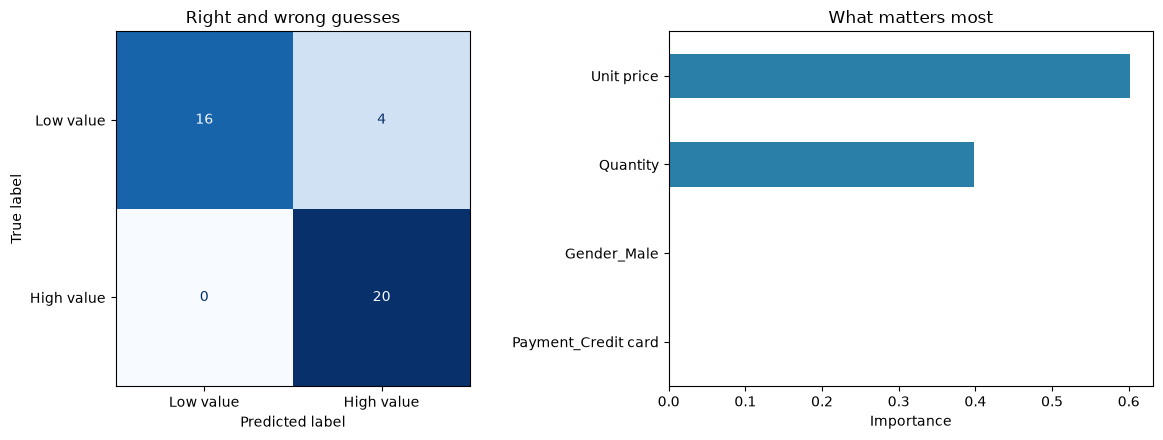

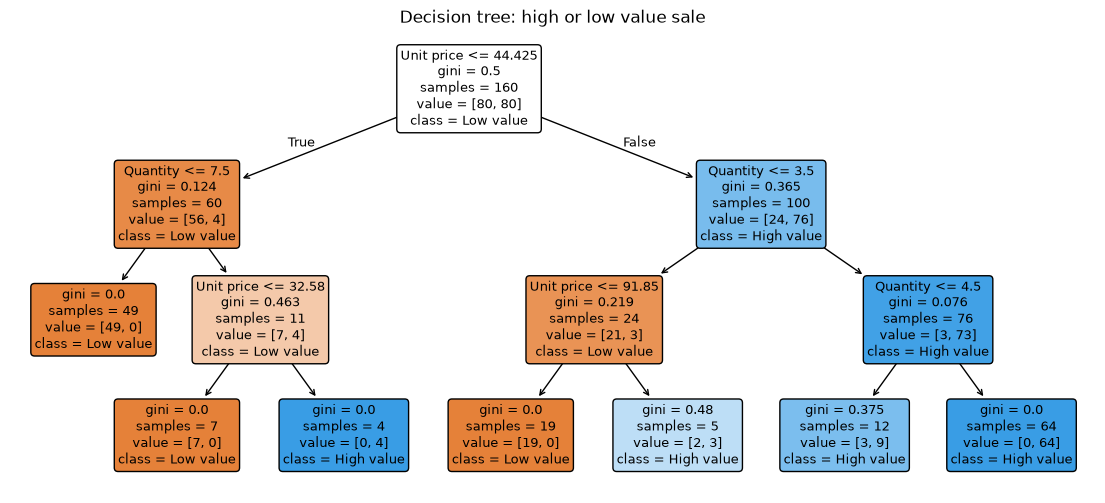

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

data = pd.read_csv("supermarket_clean.csv")
data["High value"] = (data["Total"] > data["Total"].median()).astype(int)

X = pd.get_dummies(data[["Unit price", "Quantity", "Product line", "City",
                         "Customer type", "Gender", "Payment"]], drop_first=True)
y = data["High value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
pred = tree.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, pred), 3))

# Picture 1: right and wrong guesses + what matters most
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Low value", "High value"],
    cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Right and wrong guesses")
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values().tail(4)
imp.plot(kind="barh", ax=axes[1], color="#2a7fa8")
axes[1].set_title("What matters most")
axes[1].set_xlabel("Importance")
plt.tight_layout()
plt.savefig("dt_results.png", dpi=150)
plt.show()

# Picture 2: the tree itself
plt.figure(figsize=(14, 6))
plot_tree(tree, feature_names=list(X.columns), class_names=["Low value", "High value"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision tree: high or low value sale")
plt.savefig("dt_tree.png", dpi=150, bbox_inches="tight")
plt.show()

       Unit price  Quantity  Total  Rating  Sales
Group                                            
0            74.7       8.3  645.8     6.9     65
1            27.2       5.3  153.9     7.0     72
2            72.5       2.9  230.5     6.8     63


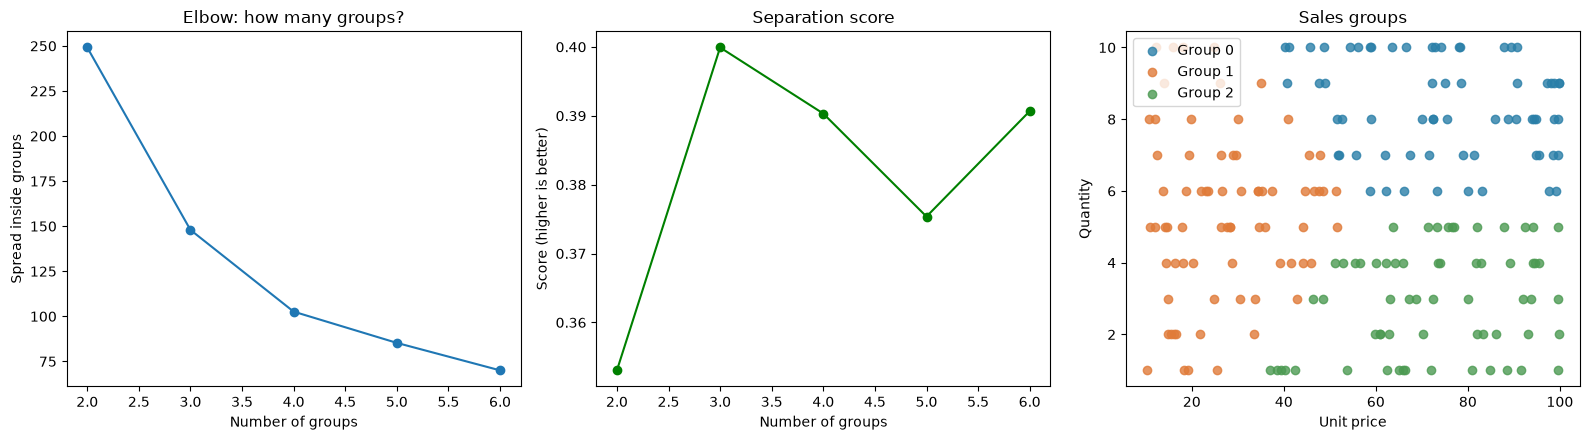

In [20]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

cols = ["Unit price", "Quantity"]
Z = StandardScaler().fit_transform(data[cols])

# Try 2 to 6 groups to see which number fits best
ks = range(2, 7)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

# Use 3 groups
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z)
data["Group"] = km.labels_

summary = data.groupby("Group")[["Unit price", "Quantity", "Total", "Rating"]].mean().round(1)
summary["Sales"] = data.groupby("Group").size()
print(summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(list(ks), inertia, marker="o")
axes[0].set_title("Elbow: how many groups?")
axes[0].set_xlabel("Number of groups"); axes[0].set_ylabel("Spread inside groups")
axes[1].plot(list(ks), sil, marker="o", color="green")
axes[1].set_title("Separation score")
axes[1].set_xlabel("Number of groups"); axes[1].set_ylabel("Score (higher is better)")
for g, c in zip(sorted(data["Group"].unique()), ["#2a7fa8", "#e07b39", "#4c9a52"]):
    s = data[data["Group"] == g]
    axes[2].scatter(s["Unit price"], s["Quantity"], label=f"Group {g}", color=c, alpha=0.8)
axes[2].set_title("Sales groups")
axes[2].set_xlabel("Unit price"); axes[2].set_ylabel("Quantity"); axes[2].legend()
plt.tight_layout()
plt.savefig("km_results.png", dpi=150)
plt.show()

Total sales: 67574.83
Average bill: 337.87
Average rating: 6.89
Best city: Yangon
Best product line: Fashion accessories
Best month: January


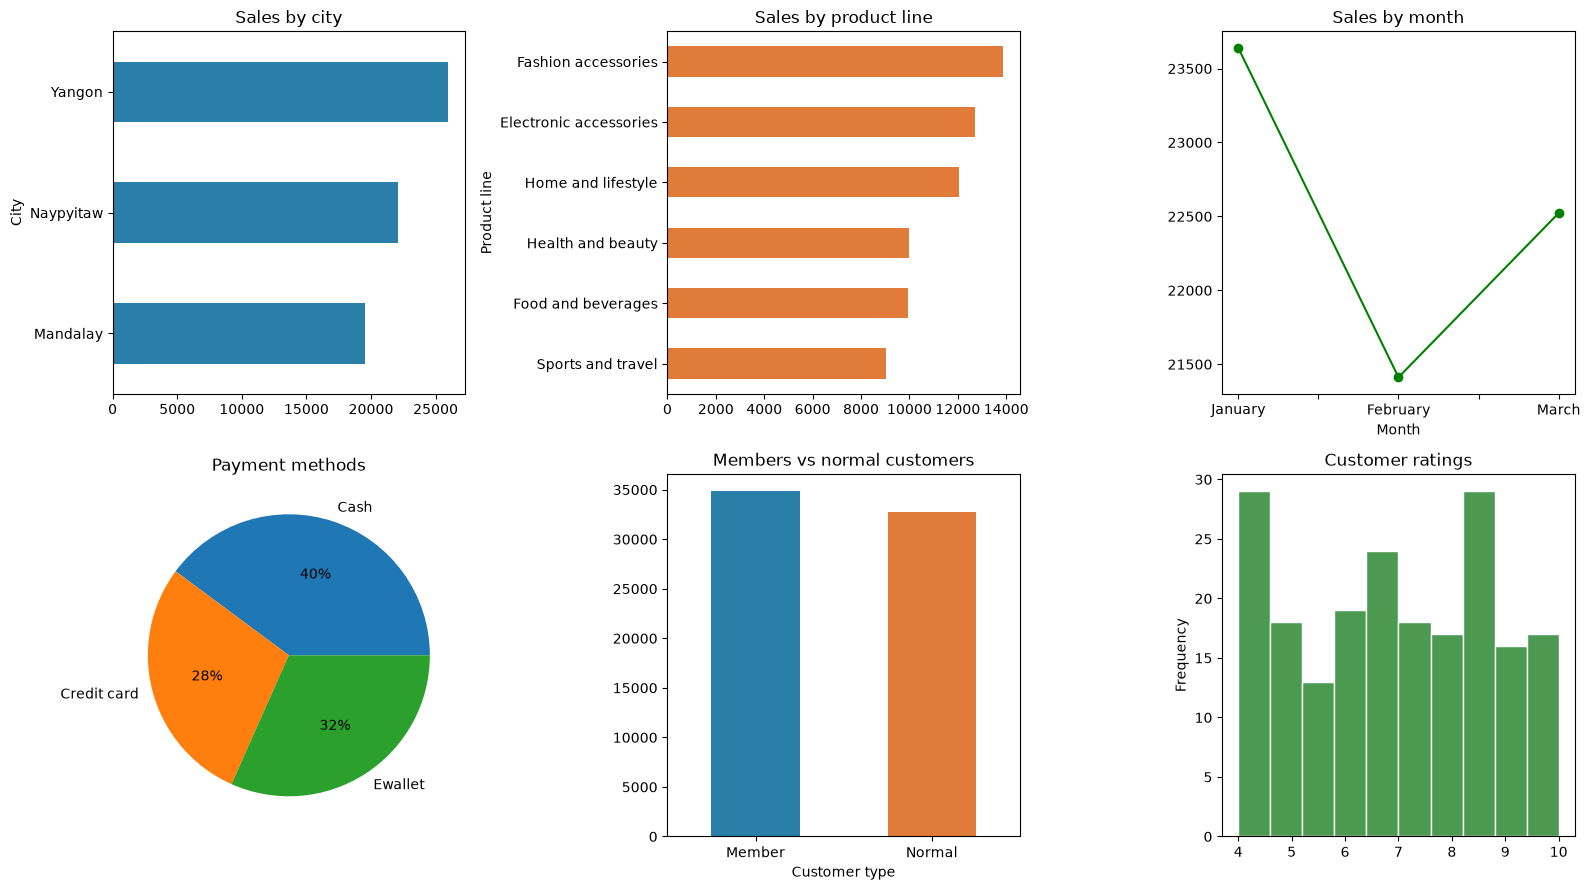

In [21]:
data = pd.read_csv("supermarket_clean.csv")

print("Total sales:", round(data["Total"].sum(), 2))
print("Average bill:", round(data["Total"].mean(), 2))
print("Average rating:", round(data["Rating"].mean(), 2))
print("Best city:", data.groupby("City")["Total"].sum().idxmax())
print("Best product line:", data.groupby("Product line")["Total"].sum().idxmax())
print("Best month:", data.groupby("Month")["Total"].sum().idxmax())

order = ["January", "February", "March"]
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
data.groupby("City")["Total"].sum().sort_values().plot(kind="barh", ax=ax[0,0], color="#2a7fa8")
ax[0,0].set_title("Sales by city")
data.groupby("Product line")["Total"].sum().sort_values().plot(kind="barh", ax=ax[0,1], color="#e07b39")
ax[0,1].set_title("Sales by product line")
data.groupby("Month")["Total"].sum().reindex(order).plot(kind="line", marker="o", ax=ax[0,2], color="green")
ax[0,2].set_title("Sales by month")
data.groupby("Payment")["Total"].sum().plot(kind="pie", ax=ax[1,0], autopct="%1.0f%%")
ax[1,0].set_ylabel(""); ax[1,0].set_title("Payment methods")
data.groupby("Customer type")["Total"].sum().plot(kind="bar", ax=ax[1,1], color=["#2a7fa8", "#e07b39"], rot=0)
ax[1,1].set_title("Members vs normal customers")
data["Rating"].plot(kind="hist", bins=10, ax=ax[1,2], color="#4c9a52", edgecolor="white")
ax[1,2].set_title("Customer ratings")
plt.tight_layout()
plt.savefig("analysis.png", dpi=120)
plt.show()